# TS04 — Classical forecasting with nested chronological selection

## Goal
Compare AR, MA, ARMA, ARIMA, exponential smoothing, damped Holt, Theta and
structural state-space methods at horizons **1–5 observed sessions**. Keep both
research tracks equally explicit, and let a baseline win model selection.
No stock smoother or hyperparameter is tuned on the outer block being evaluated.

## Observed results

Ten classical candidates were compared using three chronological outer blocks, with separate model choices for each research track. At horizon five, the selected **returns** procedure has MSE skill **-0.0273** against **zero** across **60** scored origins. At horizon five, the selected **smoothed** procedure has MSE skill **-0.1894** against **filter_nochange** across **60** scored origins. These are results on previously examined data, not an untouched holdout or an established trading advantage. Fitting failures and baseline fallbacks are retained.

## Setup
Requires statsmodels >=0.14.4 in addition to the milestone 1 environment. The notebook
is self-contained and runs offline from the frozen project snapshot. The default
experiment fits ten candidates on 252-observation training windows, with selection
before three outer blocks. This is a bounded catalogue, not exhaustive AutoARIMA.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src'/'tslab').is_dir())
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import asdict
from IPython.display import display,Markdown
from tslab.data import load_snapshot,synthetic_signal
from tslab.smoothing import FilterSpec,smooth
from tslab.evaluation import scorecard,paired_block_difference
from tslab.reporting import configure_plots,save_figure
from tslab.provenance2 import write_research_manifest
configure_plots()
SEED=1731
OUT=ROOT/'outputs'/'TS04_Classical_Forecasting_and_Selection'
OUT.mkdir(parents=True,exist_ok=True)

## Steps
### 1. Start with a known AR process
For a centered stationary process $d_t=\phi d_{t-1}+\epsilon_t$, its conditional
future mean is $\phi^h d_t$. The demonstration estimates $\phi$ on a known simulation,
before fitting any stock-data candidate. AR/MA/ARMA candidates below model changes
in the smoothed series and integrate their predicted changes back to a level.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS04_Classical_Forecasting_and_Selection/01_known_AR_control.png')


,true_phi,estimated_phi,estimated_intercept
0,0.75,0.716787,0.000354


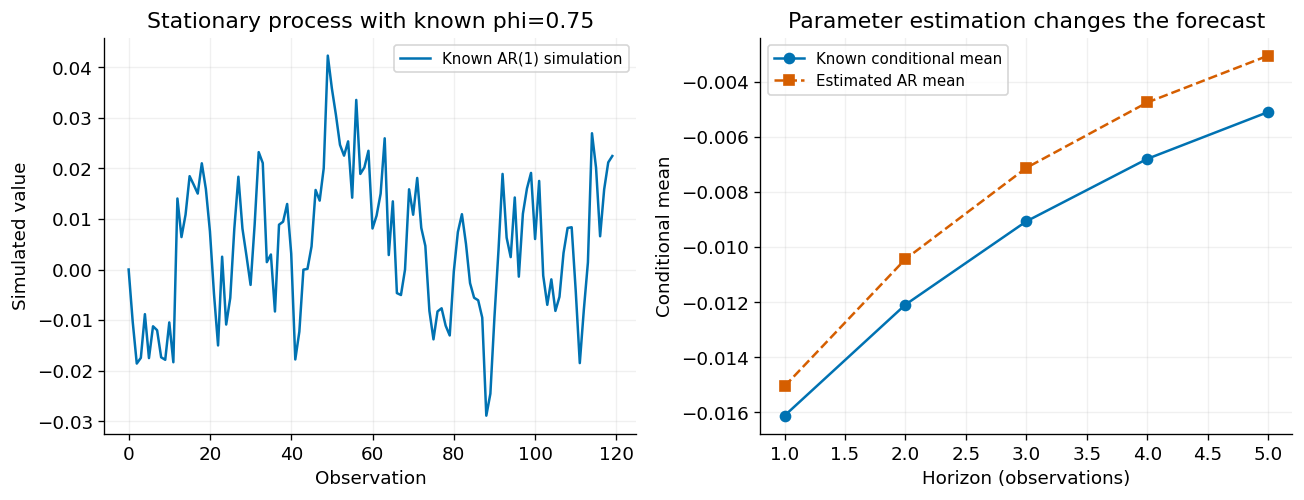

In [2]:
from tslab.classical import default_models,ModelSpec,native_forecast,fit_return_bridge,bridge_forecast
from tslab.prequential import OriginRunner,nested_benchmark
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import acf
rng=np.random.default_rng(SEED)
phi=.75
d=np.zeros(1200)
for j in range(1,len(d)):d[j]=phi*d[j-1]+rng.normal(0,.01)
estimated=AutoReg(d[:1000],lags=1,trend='c',old_names=False).fit()
h=np.arange(1,6)
estimated_mean=estimated.predict(start=1000,end=1004)
exact_mean=phi**h*d[999]
recovery=pd.DataFrame({'horizon':h,'known_conditional_mean':exact_mean,'estimated_AR_mean':estimated_mean})
recovery.to_csv(OUT/'known_AR_forecast.csv',index=False)
display(pd.DataFrame([{'true_phi':phi,'estimated_phi':estimated.params[1],'estimated_intercept':estimated.params[0]}]))
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
axes[0].plot(d[:120],label='Known AR(1) simulation')
axes[0].set(title='Stationary process with known phi=0.75',xlabel='Observation',ylabel='Simulated value')
axes[1].plot(h,exact_mean,'o-',label='Known conditional mean')
axes[1].plot(h,estimated_mean,'s--',label='Estimated AR mean')
axes[1].set(title='Parameter estimation changes the forecast',xlabel='Horizon (observations)',ylabel='Conditional mean')
for ax in axes:ax.legend(fontsize=9)
save_figure(fig,OUT,'01_known_AR_control');

### 2. State model families and targets precisely
An ARIMA$(p,d,q)$ satisfies $\phi(B)(1-B)^d s_t=c+\theta(B)\epsilon_t$ under
its chosen trend convention. SES is the nonseasonal ETS(A,N,N) point-forecast form;
damped Holt adds an evolving trend with damping $0<\varphi<1$. Theta uses the
nonseasonal theta=2 implementation. Local-level and local-linear-trend models
estimate their structural variances on the training prefix and use forward filtering.

**Track A:** native future smoothed log levels. **Track B:** an explicit two-stage
actual-return model. Fit $r_{j+1}=a+b\Delta s_j+\epsilon_{j+1}$ using only mature
labels, then propagate lagged slopes using the candidate's native smoothed path.
At horizon one all these return candidates have the same currently observed slope,
so differences across native families can appear only at horizons two through five.
The bridge is restricted and may miss information; it is not native ARIMA on returns.

In [3]:
models=default_models()
model_table=pd.DataFrame([asdict(m) for m in models])
model_table.to_csv(OUT/'model_catalogue.csv',index=False)
display(model_table)
market_x,metadata=load_snapshot(ROOT/'inputs'/'SPY_adjusted_demo.csv',ROOT/'inputs'/'SPY_adjusted_demo.metadata.json')
filter_spec=FilterSpec(kind='ema',alpha=.2,warmup=60)
settings={'outer_starts':(1000,1400,1800),'outer_step':20,'inner_count':6,'inner_step':25,
          'train_window':252,'min_success':.8}
print('Snapshot:',market_x.index[0].date(),'through',market_x.index[-1].date(),';',len(market_x),'observed sessions')

Snapshot: 2018-01-02 through 2026-10-01 ; 2199 observed sessions


,name,family,lags,order
0,AR1_changes,ar_diff,1,"(1, 1, 1)"
1,AR5_changes,ar_diff,5,"(1, 1, 1)"
2,MA1_changes,arma_diff,1,"(0, 0, 1)"
3,ARMA11_changes,arma_diff,1,"(1, 0, 1)"
4,ARIMA111,arima,1,"(1, 1, 1)"
5,SES_ETS_ANN,ses,1,"(1, 1, 1)"
6,Holt_damped,holt,1,"(1, 1, 1)"
7,Theta2,theta,1,"(1, 1, 1)"
8,Local_level,local_level,1,"(1, 1, 1)"
9,Local_linear_trend,local_trend,1,"(1, 1, 1)"


### 3. Fit and select using nested chronological windows
Before each outer block, evaluate all ten candidates at six earlier inner origins.
The final five-session inner label must end before the first outer origin. For each
track, choose the candidate with minimum mean relative MAE across the five horizons,
or the track baseline if it scores better. A candidate must fit successfully at
at least 80% of inner origins; otherwise it is ineligible for selection.

Refit model parameters at every scheduled origin using only the most recent 252
mature smoothed observations. Return calibration labels end no later than that origin.
Record all errors/warnings. Failed native fits fall back to the unchanged-path
smoothed baseline or zero return, retaining every scheduled comparison date.

In [4]:
run=nested_benchmark(market_x,models,filter_spec=filter_spec,**settings)
records=run['forecasts']
scores=scorecard(records)
for name in ['forecasts','inner_forecasts','selections','tuning','fit_audit']:
    filename='historical_forecasts.csv' if name=='forecasts' else name+'.csv'
    run[name].to_csv(OUT/filename,index=False)
run['smoothed'].to_csv(OUT/'causal_smoothed_target.csv',index_label='Date')
for track in ['smoothed','returns']:
    scores[scores.track==track].to_csv(OUT/f'{track}_scorecard.csv',index=False)
display(run['selections'][['block','track','chosen_model','selection_cutoff','outer_first_origin','inner_last_label']])
assert (run['selections'].inner_last_label<=run['selections'].selection_cutoff).all()
assert (run['selections'].selection_cutoff<run['selections'].outer_first_origin).all()

,block,track,chosen_model,selection_cutoff,outer_first_origin,inner_last_label
0,0,smoothed,Holt_damped,2021-12-20,2021-12-21,2021-12-20
1,0,returns,ARMA11_changes,2021-12-20,2021-12-21,2021-12-20
2,1,smoothed,Local_linear_trend,2023-07-26,2023-07-27,2023-07-26
3,1,returns,zero,2023-07-26,2023-07-27,2023-07-26
4,2,smoothed,AR5_changes,2025-02-28,2025-03-03,2025-02-28
5,2,returns,zero,2025-02-28,2025-03-03,2025-02-28


The outer-origin schedule advances by 20 observed sessions. It is a computationally
bounded forecast experiment, not a daily trading simulation. Final origins whose
future labels have not matured are retained as forecasts and excluded from scores.
The candidate catalogue and selection protocol are fixed for this demonstration;
the underlying SPY period is previously examined, so this is not a pristine holdout.

### 4. Inspect separate scorecards and the selected procedure
The selected pipeline is a procedure that can choose different models by block and
track. Report its losses on outer origins; do not select the best-looking outer model
after seeing the table and call that result validation.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS04_Classical_Forecasting_and_Selection/02_separate_outer_scorecards.png')


,model,n,MAE,RMSE,MSE_skill
130,AR1_changes,60,0.009237,0.012058,-0.031324
131,AR5_changes,60,0.009586,0.012530,-0.113607
132,ARIMA111,60,0.009382,0.012102,-0.038807
133,ARMA11_changes,60,0.009384,0.012108,-0.039992
134,Holt_damped,60,0.009270,0.011951,-0.013139
135,Local_level,60,0.013561,0.016554,-0.943827
136,Local_linear_trend,60,0.010064,0.013760,-0.343113
137,MA1_changes,60,0.012045,0.015329,-0.666713
138,SES_ETS_ANN,60,0.013559,0.016465,-0.922918
139,Theta2,60,0.013229,0.016462,-0.922335


,model,n,MAE,RMSE,MSE_skill
56,AR1_changes,60,0.019449,0.026690,-0.028036
57,AR5_changes,60,0.019387,0.026628,-0.023233
58,ARIMA111,60,0.019446,0.026684,-0.027568
59,ARMA11_changes,60,0.019445,0.026683,-0.027467
60,Holt_damped,60,0.019616,0.026813,-0.037538
61,Local_level,60,0.019244,0.026622,-0.022787
62,Local_linear_trend,60,0.019983,0.027143,-0.063184
63,MA1_changes,60,0.019019,0.026378,-0.004133
64,SES_ETS_ANN,60,0.019061,0.026413,-0.006786
65,Theta2,60,0.018976,0.026351,-0.002053


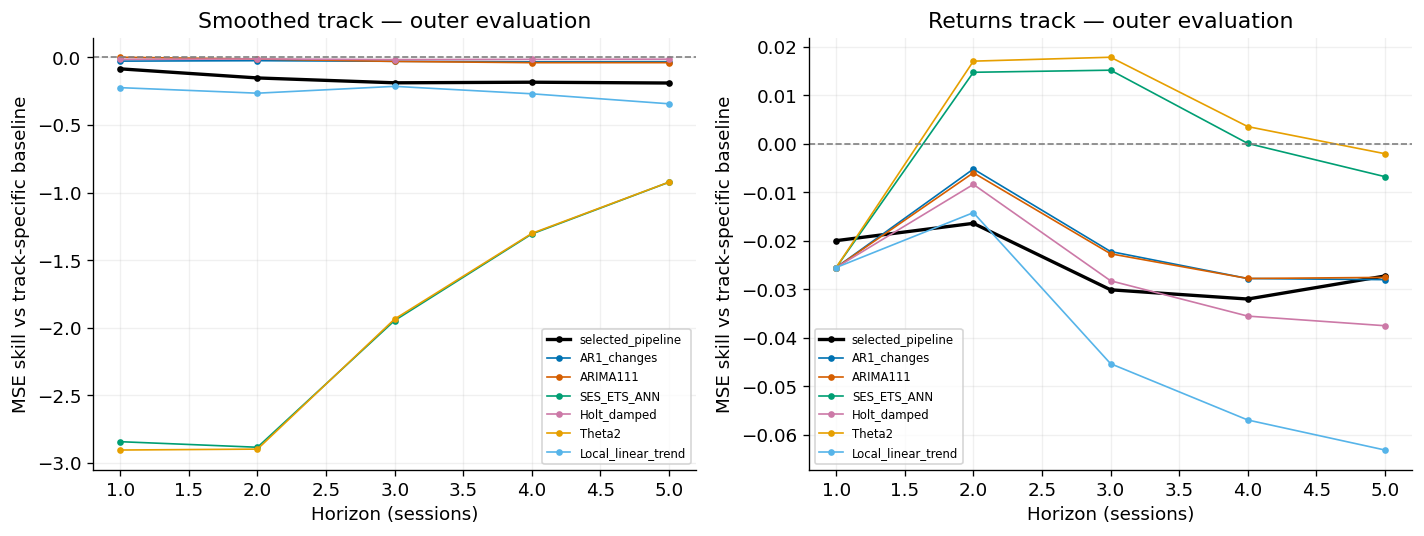

In [5]:
for track in ['smoothed','returns']:
    display(scores.query('track==@track and horizon==5')[['model','n','MAE','RMSE','MSE_skill']].round(6))
show=['selected_pipeline','AR1_changes','ARIMA111','SES_ETS_ANN','Holt_damped','Theta2','Local_linear_trend']
colors=dict(zip(show,['black','#0072B2','#D55E00','#009E73','#CC79A7','#E69F00','#56B4E9']))
fig,axes=plt.subplots(1,2,figsize=(12,4.6))
for ax,track in zip(axes,['smoothed','returns']):
    for name in show:
        group=scores[(scores.track==track)&(scores.model==name)]
        ax.plot(group.horizon,group.MSE_skill,marker='o',ms=3,lw=2 if name=='selected_pipeline' else 1,
                color=colors[name],label=name)
    ax.axhline(0,color='.5',ls='--',lw=1)
    ax.set(title=f'{track.title()} track — outer evaluation',xlabel='Horizon (sessions)',ylabel='MSE skill vs track-specific baseline')
    ax.legend(fontsize=7)
save_figure(fig,OUT,'02_separate_outer_scorecards');

### 5. Make fit availability and failures visible
These rates include every inner and outer fit once (cached origin/model fits are
not counted twice). Convergence failures invoke the declared fallback and remain in
operational losses. Warnings from successful fits are retained in the audit file.
High forecast accuracy at very low fitting availability must not be hidden.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS04_Classical_Forecasting_and_Selection/03_fit_availability.png')


,model,track,n_fits,successful_fraction,mean_runtime_seconds
0,AR1_changes,returns,79,1.0000,0.0021
1,AR1_changes,smoothed,79,1.0000,0.0015
2,AR5_changes,returns,79,1.0000,0.0022
3,AR5_changes,smoothed,79,1.0000,0.0013
4,ARIMA111,returns,79,0.9620,0.0357
5,ARIMA111,smoothed,79,0.9620,0.0351
6,ARMA11_changes,returns,79,1.0000,0.0160
7,ARMA11_changes,smoothed,79,1.0000,0.0155
8,Holt_damped,returns,79,1.0000,0.0077
9,Holt_damped,smoothed,79,1.0000,0.0072


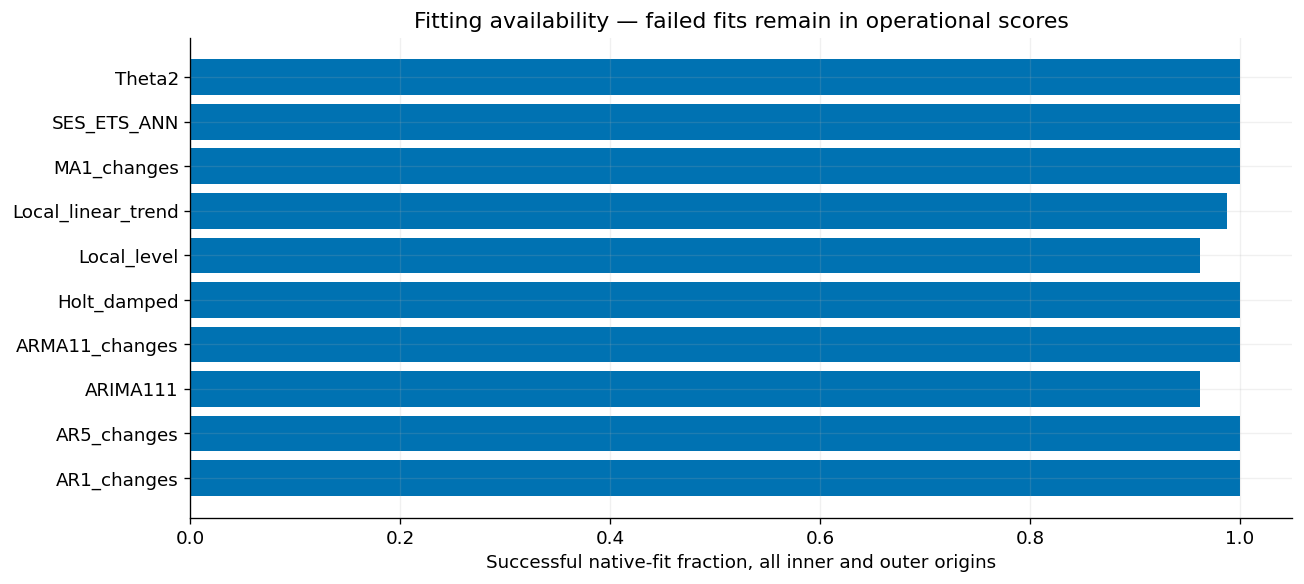

In [6]:
availability=run['fit_audit'].groupby(['model','track']).agg(
    n_fits=('fit_status','size'),successful_fraction=('fit_status',lambda x:(x=='ok').mean()),
    mean_runtime_seconds=('runtime_seconds','mean')).reset_index()
availability.to_csv(OUT/'fit_availability.csv',index=False)
display(availability.round(4))
fig,ax=plt.subplots(figsize=(11,5))
part=availability[availability.track=='smoothed'].sort_values('model')
ax.barh(part.model,part.successful_fraction,color='#0072B2')
ax.set(xlim=(0,1.05),xlabel='Successful native-fit fraction, all inner and outer origins',
       title='Fitting availability — failed fits remain in operational scores')
save_figure(fig,OUT,'03_fit_availability');

### 6. Diagnose a calibration fit without selecting on outer residuals
Inspect standardized residual autocorrelation for a predeclared AR(1)-on-smoothed-
changes model at the first calibration cutoff. ACF is a diagnostic, not proof of
independent errors or predictive adequacy. Native models use smoothed targets;
therefore good residual behavior alone says little about actual-return skill.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS04_Classical_Forecasting_and_Selection/04_calibration_residual_ACF.png')


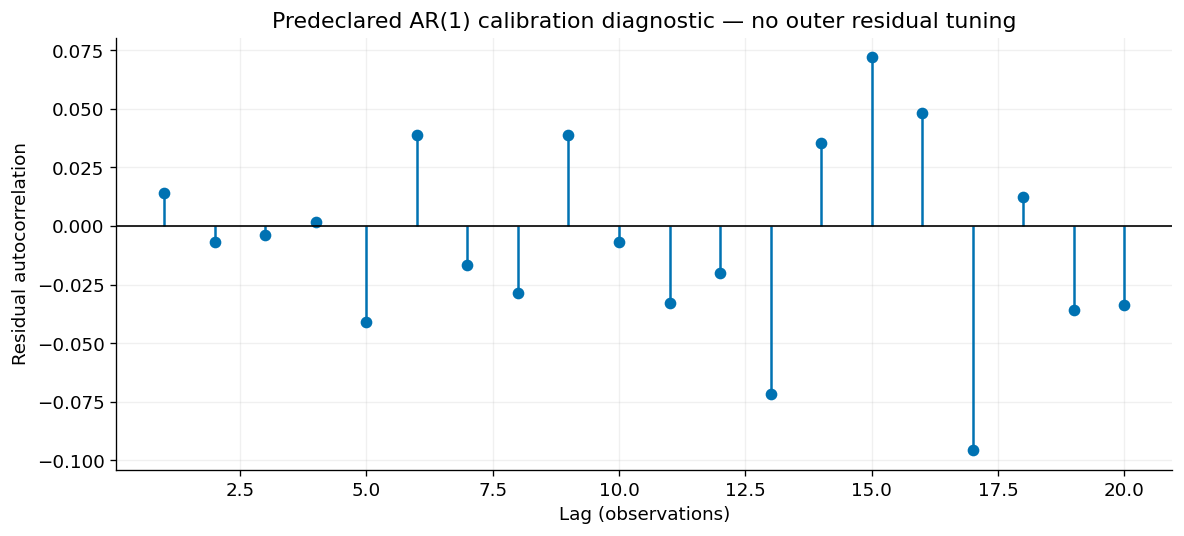

In [7]:
origin=settings['outer_starts'][0]-1
prefix=run['smoothed'].iloc[:origin+1].dropna().to_numpy()
_,diag=native_forecast(prefix,models[0],train_window=settings['train_window'])
residual=diag['residuals']
residual=residual[np.isfinite(residual)]
correlation=acf(residual,nlags=20,fft=False)
pd.DataFrame({'lag':np.arange(len(correlation)),'residual_ACF':correlation}).to_csv(OUT/'calibration_residual_ACF.csv',index=False)
fig,ax=plt.subplots()
ax.stem(np.arange(1,len(correlation)),correlation[1:],basefmt=' ')
ax.axhline(0,color='black',lw=1)
ax.set(xlabel='Lag (observations)',ylabel='Residual autocorrelation',
       title='Predeclared AR(1) calibration diagnostic — no outer residual tuning')
save_figure(fig,OUT,'04_calibration_residual_ACF');

### 7. Quantify paired uncertainty for the selected procedure
Compare the outer selected pipeline against each track's benchmark at horizon five.
Use moving blocks of scheduled origins; one origin interval is 20 sessions here.
Show three block lengths. These percentile ranges are exploratory conditional
comparisons, not a correction for prior research, model search or nonstationarity.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS04_Classical_Forecasting_and_Selection/05_paired_uncertainty.png')


,track,mean_MAE_difference,lower95,upper95,n_origins,block_origins,draws
0,smoothed,0.000467,-0.000291,0.001162,60,2,2000
1,smoothed,0.000467,-0.000304,0.001270,60,4,2000
2,smoothed,0.000467,-0.000225,0.001395,60,8,2000
3,returns,0.000238,-0.000180,0.000861,60,2,2000
4,returns,0.000238,-0.000120,0.000686,60,4,2000
5,returns,0.000238,-0.000131,0.000616,60,8,2000


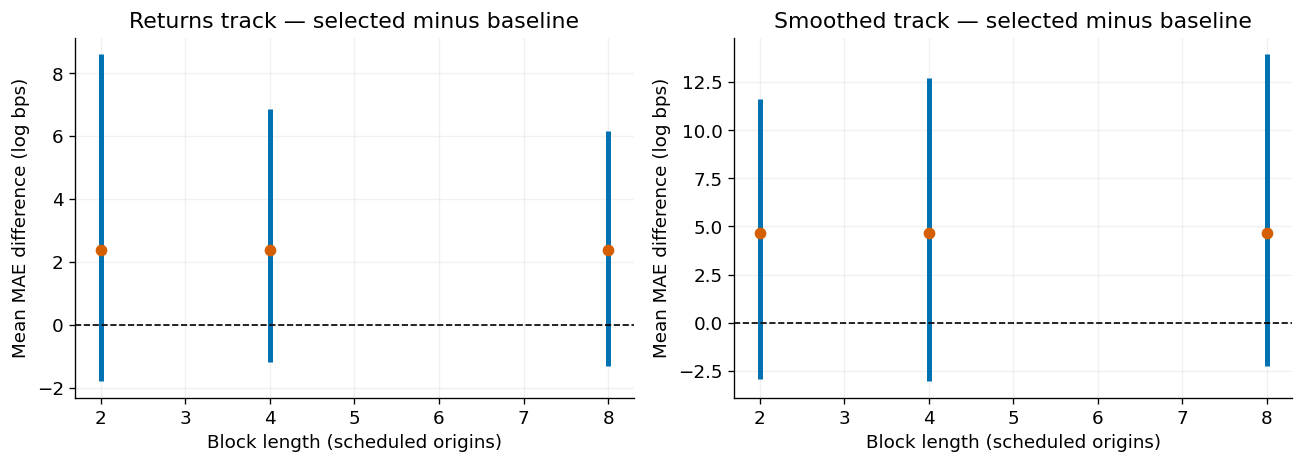

In [8]:
uncertainty=[]
for track,baseline in [('smoothed','filter_nochange'),('returns','zero')]:
    for block in [2,4,8]:
        row=paired_block_difference(records,track,'selected_pipeline',baseline,horizon=5,block=block,draws=2000,seed=SEED)
        uncertainty.append({'track':track,**row})
uncertainty=pd.DataFrame(uncertainty)
uncertainty.to_csv(OUT/'selected_paired_uncertainty.csv',index=False)
display(uncertainty.round(7))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,(track,part) in zip(axes,uncertainty.groupby('track')):
    ax.vlines(part.block_origins,part.lower95*1e4,part.upper95*1e4,color='#0072B2',lw=3)
    ax.plot(part.block_origins,part.mean_MAE_difference*1e4,'o',color='#D55E00')
    ax.axhline(0,color='black',ls='--',lw=1)
    ax.set(title=f'{track.title()} track — selected minus baseline',xlabel='Block length (scheduled origins)',
           ylabel='Mean MAE difference (log bps)')
save_figure(fig,OUT,'05_paired_uncertainty');

## Checks
Check historical selection cutoffs, mature bridge labels, identical comparison
origins, frozen current-prefix forecasts under future poisoning, and saved endpoint
forecasts. The full test suite also forces a model failure to verify fallback accounting.

In [9]:
from tslab.prequential import OriginRunner
probe=int(settings['outer_starts'][0])
original=OriginRunner(market_x.iloc[:probe+6],models[:2],filter_spec).predictions(probe)
poison=market_x.iloc[:probe+6].copy();poison.iloc[probe+1:]+=100
contaminated=OriginRunner(poison,models[:2],filter_spec).predictions(probe)
pd.testing.assert_frame_equal(original,contaminated)
assert (run['fit_audit'].bridge_last_label_pos<=run['fit_audit'].origin_pos).all()
assert scores.groupby(['track','horizon']).n.nunique().eq(1).all()
latest=records[records.origin==market_x.index[-1]]
assert latest.status.eq('immature').all()
latest.to_csv(OUT/'latest_forecasts.csv',index=False)
display(latest[latest.model=='selected_pipeline'][['origin','track','horizon','chosen_model','prediction','fit_status','status']])
checks={'selection_before_outer':True,'bridge_labels_mature':True,'common_outer_origins':True,
        'future_poison_invariant':True,'latest_forecasts_unscored':True}
(OUT/'checks.json').write_text(json.dumps(checks,indent=2))
write_research_manifest(OUT,{'filter':asdict(filter_spec),'models':[asdict(m) for m in models],**settings,
    'selection_objective':'equal-horizon relative MAE, separately per track',
    'fallbacks':{'smoothed':'filter_nochange','returns':'zero'},
    'return_bridge':'OLS next raw return on current smoothed slope'},metadata,seed=SEED)
selected=scores[(scores.model=='selected_pipeline')&(scores.horizon==5)]
summary='## Observed results\n\nTen classical candidates were compared using three chronological outer blocks, with separate model choices for each research track. '
for row in selected.itertuples():
    summary+=f"At horizon five, the selected **{row.track}** procedure has MSE skill **{row.MSE_skill:.4f}** against **{row.baseline}** across **{row.n}** scored origins. "
summary+='These are results on previously examined data, not an untouched holdout or an established trading advantage. Fitting failures and baseline fallbacks are retained.'
(OUT/'observed_summary.md').write_text(summary)
print('PASS: selection timing, bridge maturity, prefix forecasts and matched-origin checks.')

PASS: selection timing, bridge maturity, prefix forecasts and matched-origin checks.


,origin,track,horizon,chosen_model,prediction,fit_status,status
8835,2026-10-01,smoothed,1,AR5_changes,6.639897,ok,immature
8836,2026-10-01,smoothed,2,AR5_changes,6.639897,ok,immature
8837,2026-10-01,smoothed,3,AR5_changes,6.640032,ok,immature
8838,2026-10-01,smoothed,4,AR5_changes,6.640266,ok,immature
8839,2026-10-01,smoothed,5,AR5_changes,6.640575,ok,immature
8840,2026-10-01,returns,1,zero,0.000000,baseline,immature
8841,2026-10-01,returns,2,zero,0.000000,baseline,immature
8842,2026-10-01,returns,3,zero,0.000000,baseline,immature
8843,2026-10-01,returns,4,zero,0.000000,baseline,immature
8844,2026-10-01,returns,5,zero,0.000000,baseline,immature


## Next Steps
TS05 will add lagged tabular ML, and TS06 compact neural models, using these same
target and chronological-evaluation contracts. More ARIMA orders, seasonality and
exogenous regressors belong in separate declared grids and appropriate datasets.
Do not impose a five-session seasonal cycle just because horizons run to five.

References: [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html),
[exponential smoothing](https://www.statsmodels.org/stable/examples/notebooks/generated/exponential_smoothing.html),
[Theta](https://www.statsmodels.org/stable/generated/statsmodels.tsa.forecasting.theta.ThetaModel.html),
[state-space forecasting](https://www.statsmodels.org/stable/examples/notebooks/generated/statespace_forecasting.html).